# Logistic Regression: From a Line to a Probability
**Beginner classroom notebook · one feature · two outcomes**

Can study hours help estimate whether a student passes? We will build a model that outputs a probability, choose a decision threshold, and inspect mistakes.

**You will learn:** why a line is not a probability; how sigmoid fixes the output range; how training uses log loss; and how probabilities become decisions.

**How to use:** upload this `.ipynb` file through Google Colab's **File → Upload notebook**. Run cells from top to bottom using the play button or Shift+Enter. A CPU runtime is enough. Saved outputs are included; rerunning replaces them. No dataset download, Drive mount, API key, or package-install cell is needed in a standard Colab Python runtime.

**Assumed knowledge:** a straight-line equation and basic Python. Follow sections 1–9 for the core lesson. Everything after **Optional extension** can wait.

> All student data below is simulated. The exercise demonstrates a workflow, not evidence about actual students or the causal effect of studying. A real support system would require richer data and careful evaluation.


## 1. Set up the tools
`numpy` handles numerical work; `pandas` shows tables; `matplotlib` draws graphs; `scikit-learn` supplies the models and metrics.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
import sklearn

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11})
print('scikit-learn version:', sklearn.__version__)
print('Positive class: 1 = pass; negative class: 0 = fail.')


scikit-learn version: 1.8.0
Positive class: 1 = pass; negative class: 0 = fail.


## 2. Create and inspect our classroom data
Each row describes one fictional student. `hours_studied` is the input $x$; `passed` is the label $y$.

The generator makes passing generally more likely at higher study hours, while retaining uncertainty. The random seed makes this demonstration reproducible. We know the generator only because this is simulated data; a trained model never receives the hidden probabilities.

**Discuss:** must two students with the same study time have the same outcome?


In [2]:
rng = np.random.default_rng(42)
hours = rng.uniform(0, 10, size=240)
# Hidden data-generating rule, used only to simulate classroom outcomes.
hidden_probability = 1 / (1 + np.exp(-(-4 + 0.8 * hours)))
passed = rng.binomial(1, hidden_probability)
data = pd.DataFrame({'hours_studied': hours, 'passed': passed})
display(data.head(8).round(2))
print('Number of examples:', len(data))
print('Observed pass fraction:', round(data['passed'].mean(), 3))


,hours_studied,passed
0,7.74,1
1,4.39,1
2,8.59,1
3,6.97,1
4,0.94,0
5,9.76,1
6,7.61,1
7,7.86,1


Number of examples: 240
Observed pass fraction: 0.446


### Hold back examples before fitting
The training set teaches the model. The test set is held back to evaluate new-example predictions. `stratify=y` approximately preserves the class proportions in each set.

We will illustrate thresholds on **training** data and evaluate the prespecified threshold 0.5 on the test set once. A full model-selection workflow would add validation data.


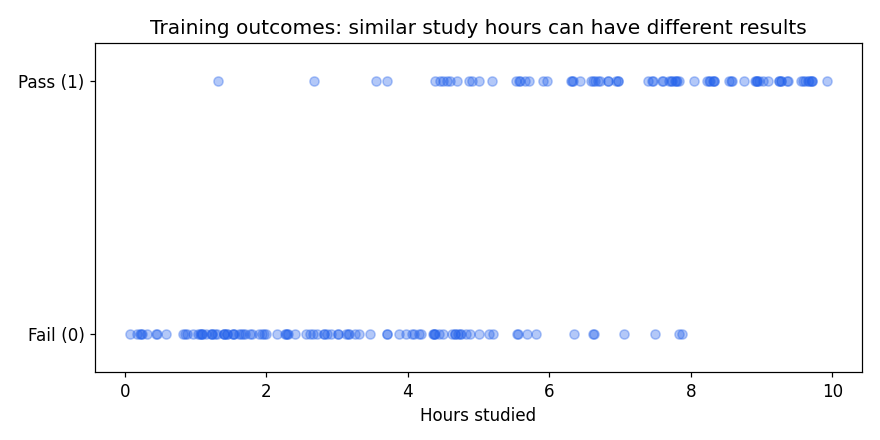

Training examples: 180; test examples: 60


In [3]:
X = data[['hours_studied']]  # A two-dimensional feature table.
y = data['passed']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=7, stratify=y
)
print(f'Training examples: {len(X_train)}; test examples: {len(X_test)}')
plt.scatter(X_train['hours_studied'], y_train, alpha=0.35, color='#2563eb')
plt.yticks([0, 1], ['Fail (0)', 'Pass (1)'])
plt.xlabel('Hours studied')
plt.title('Training outcomes: similar study hours can have different results')
plt.ylim(-0.15, 1.15)
plt.tight_layout()
plt.show()


## 3. Why a straight line is not a probability
Linear regression fits $hat y=b+wx$. Even with 0/1 training labels, its predictions are unbounded.

**Predict before running:** can the fitted line produce a value below 0 or above 1?


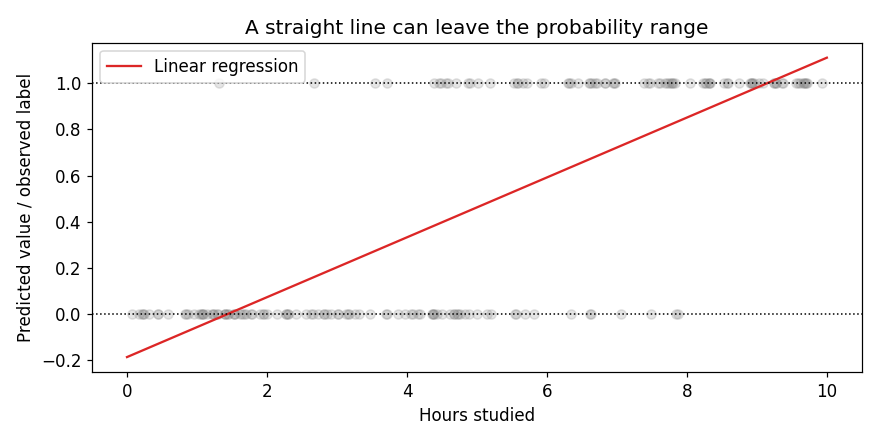

Predicted range on 0–10 hours: -0.186 to 1.111
Clipping this line would not fit a logistic regression model.


In [4]:
linear_model = LinearRegression().fit(X_train, y_train)
grid = pd.DataFrame({'hours_studied': np.linspace(0, 10, 300)})
linear_predictions = linear_model.predict(grid)
plt.scatter(X_train['hours_studied'], y_train, alpha=0.2, color='gray')
plt.plot(grid['hours_studied'], linear_predictions, color='#dc2626', label='Linear regression')
plt.axhline(0, color='black', linestyle=':', linewidth=1)
plt.axhline(1, color='black', linestyle=':', linewidth=1)
plt.xlabel('Hours studied')
plt.ylabel('Predicted value / observed label')
plt.title('A straight line can leave the probability range')
plt.legend()
plt.tight_layout()
plt.show()
print('Predicted range on 0–10 hours:', linear_predictions.min().round(3), 'to', linear_predictions.max().round(3))
print('Clipping this line would not fit a logistic regression model.')


## 4. From a linear score to a probability
Keep the score $z=b+wx$. Model the **log-odds** as this score:

$$\log\left(\frac{p}{1-p}\right)=z.$$

Exponentiate and rearrange:

$$\frac{p}{1-p}=e^z \quad\Rightarrow\quad p=e^z(1-p)
\quad\Rightarrow\quad p=\frac{1}{1+e^{-z}}.$$

This is the **sigmoid**, $\sigma(z)$. It maps a real score to a probability between 0 and 1. We chose to make log-odds linear; this is a new modeling assumption, not an algebraic consequence of ordinary least squares.

**Checkpoint:** what is $\sigma(0)$? What happens when the score becomes very positive?


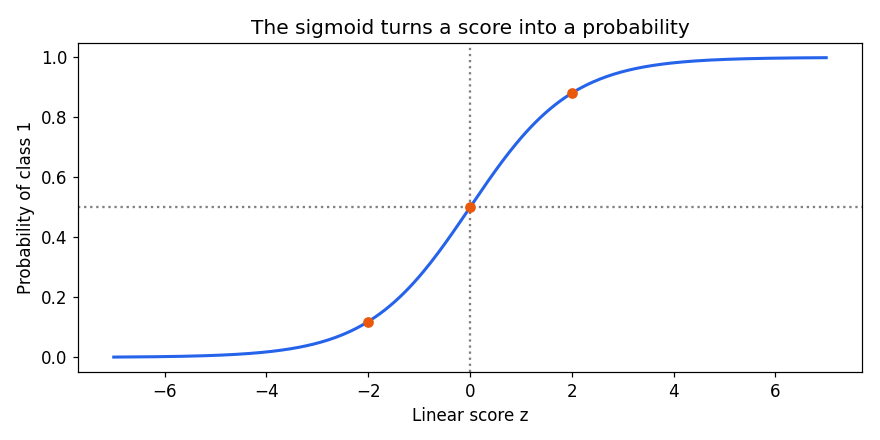

Scores -2, 0, 2 map to: [0.119 0.5   0.881]


In [5]:
def sigmoid(z):
    # Clipping here only avoids numerical overflow for extreme demo inputs.
    return 1 / (1 + np.exp(-np.clip(np.asarray(z, dtype=float), -500, 500)))

scores = np.linspace(-7, 7, 300)
plt.plot(scores, sigmoid(scores), color='#2563eb', linewidth=2)
plt.scatter([-2, 0, 2], sigmoid([-2, 0, 2]), color='#ea580c', zorder=3)
plt.axhline(0.5, color='gray', linestyle=':')
plt.axvline(0, color='gray', linestyle=':')
plt.xlabel('Linear score z')
plt.ylabel('Probability of class 1')
plt.title('The sigmoid turns a score into a probability')
plt.tight_layout()
plt.show()
print('Scores -2, 0, 2 map to:', sigmoid([-2, 0, 2]).round(3))


### Try hand-chosen weights
Use $b=-4$ and $w=0.8$. These are illustrative values, not learned model coefficients.
For six hours: $z=-4+0.8(6)=0.8$ and $p\approx0.690$.

A 69% estimated chance of passing is not an exam score of 69%.


In [6]:
example_hours = np.array([2, 5, 6, 8])
example_scores = -4 + 0.8 * example_hours
example_probabilities = sigmoid(example_scores)
display(pd.DataFrame({
    'hours': example_hours,
    'score': example_scores,
    'P(pass)': example_probabilities,
    'prediction_at_0.5': (example_probabilities >= 0.5).astype(int)
}).round(3))


,hours,score,P(pass),prediction_at_0.5
0,2,-2.4,0.083,0
1,5,0.0,0.500,1
2,6,0.8,0.690,1
3,8,2.4,0.917,1


## 5. How training knows what is better
For one example, **log loss** is:

$$\ell(y,p)=-[y\log p+(1-y)\log(1-p)].$$

When the actual label is 1, the loss becomes $-\log p$. Assigning high probability to the observed result gives lower loss. Confident mistakes get a large penalty.

Training finds weights that reduce average loss. Our library model also uses default regularization, which discourages overly large weights. The optimization mathematics is optional.

**Predict:** if the student actually passes, is 0.9 or 0.1 the better probability prediction?


In [7]:
trial_probabilities = np.array([0.9, 0.5, 0.1])
display(pd.DataFrame({
    'actual_label': [1, 1, 1],
    'predicted_P(pass)': trial_probabilities,
    'log_loss': -np.log(trial_probabilities)
}).round(3))


,actual_label,predicted_P(pass),log_loss
0,1,0.9,0.105
1,1,0.5,0.693
2,1,0.1,2.303


## 6. Train logistic regression and inspect its curve
`fit` learns the intercept and coefficient from the training examples. `predict_proba` returns one probability column for each entry in `classes_`; we explicitly find the column for label 1.

We keep hours in their original units for easy interpretation. With many features in different units, scaling in a preprocessing pipeline becomes useful.


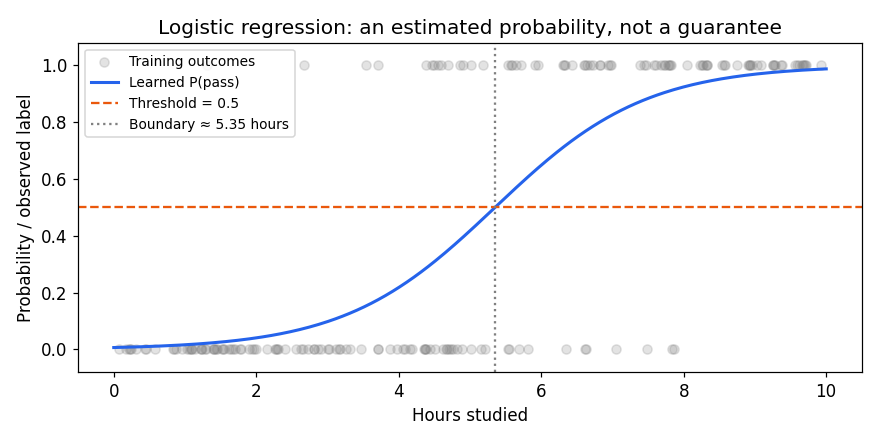

Learned score: z = -5.059 + (0.945 × hours)
Probability-column labels: [0 1]
A positive coefficient raises P(pass), not by a fixed number of percentage points.


In [8]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pass_column = list(model.classes_).index(1)
b = float(model.intercept_[0])
w = float(model.coef_[0, 0])
print(f'Learned score: z = {b:.3f} + ({w:.3f} × hours)')
print('Probability-column labels:', model.classes_)
print('A positive coefficient raises P(pass), not by a fixed number of percentage points.')

curve_probability = model.predict_proba(grid)[:, pass_column]
plt.scatter(X_train['hours_studied'], y_train, alpha=0.22, color='gray', label='Training outcomes')
plt.plot(grid['hours_studied'], curve_probability, color='#2563eb', linewidth=2, label='Learned P(pass)')
plt.axhline(0.5, color='#ea580c', linestyle='--', label='Threshold = 0.5')
if abs(w) > 1e-12:
    boundary = -b / w
    if 0 <= boundary <= 10:
        plt.axvline(boundary, color='gray', linestyle=':', label=f'Boundary ≈ {boundary:.2f} hours')
plt.xlabel('Hours studied')
plt.ylabel('Probability / observed label')
plt.title('Logistic regression: an estimated probability, not a guarantee')
plt.ylim(-0.08, 1.08)
plt.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()


## 7. Same probabilities, different decisions
We predict pass when $p\ge t$.

**Positive = pass.** A false positive predicts pass for someone who fails. A false negative predicts fail for someone who passes.

In our support scenario, students predicted to fail are offered support. Raising the pass threshold offers support to more students, including some who would pass anyway.

The following is a **training-set illustration**, not an unbiased performance report. Do not choose a threshold based on the test set.


In [9]:
train_probabilities = model.predict_proba(X_train)[:, pass_column]
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    decisions = (train_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, decisions, labels=[0, 1]).ravel()
    threshold_rows.append({
        'pass_threshold': threshold,
        'predicted_pass': int(decisions.sum()),
        'offered_support': int((decisions == 0).sum()),
        'false_pass_FP': fp,
        'false_fail_FN': fn
    })
display(pd.DataFrame(threshold_rows))
print('Increasing the threshold changes decisions; it does not retrain the model.')


,pass_threshold,predicted_pass,offered_support,false_pass_FP,false_fail_FN
0,0.3,98,82,23,5
1,0.5,77,103,11,14
2,0.7,66,114,7,21


Increasing the threshold changes decisions; it does not retrain the model.


## 8. Evaluate on held-out students
We fixed the test threshold at 0.5 in advance. The matrix has **actual labels in rows**, **predicted labels in columns**. Accuracy is the fraction of correct decisions.

Compare against a baseline that always predicts the most common **training** label. Class proportions and error costs matter: accuracy alone cannot tell the whole story.


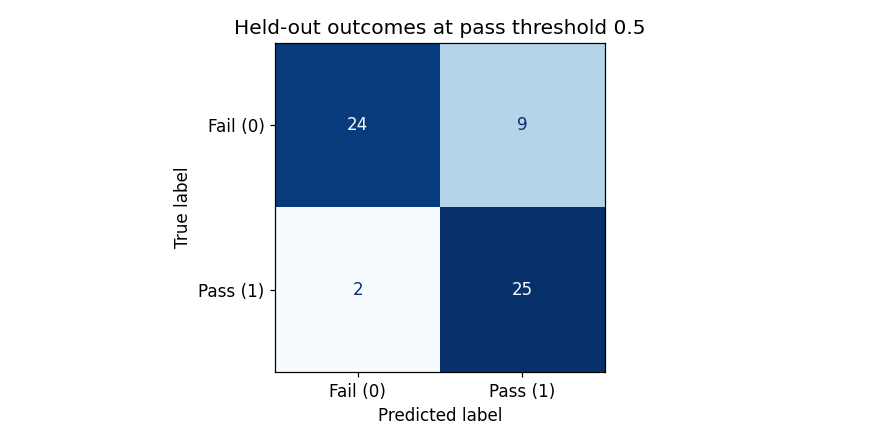

Logistic regression test accuracy: 81.7%
Majority-class baseline accuracy: 55.0%
Predicted pass but actually failed (FP): 9
Predicted fail but actually passed (FN): 2
These are simulated held-out results, not evidence of real-world educational performance.


In [10]:
test_probabilities = model.predict_proba(X_test)[:, pass_column]
fixed_threshold = 0.5
test_predictions = (test_probabilities >= fixed_threshold).astype(int)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
print(f'Logistic regression test accuracy: {accuracy_score(y_test, test_predictions):.1%}')
print(f'Majority-class baseline accuracy: {accuracy_score(y_test, baseline_predictions):.1%}')
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Fail (0)', 'Pass (1)']).plot(cmap='Blues', colorbar=False)
plt.title('Held-out outcomes at pass threshold 0.5')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'Predicted pass but actually failed (FP): {fp}')
print(f'Predicted fail but actually passed (FN): {fn}')
print('These are simulated held-out results, not evidence of real-world educational performance.')


## 9. Predict for a new example
Change `new_hours`, then rerun this cell. Keep values within the simulated 0–10-hour range.

**Before running:** what changes if we raise the decision threshold to 0.7? What stays the same?


In [11]:
new_hours = 6.0  # Student activity: try 2.0, 5.0, and 8.0.
new_threshold = 0.5  # Then try 0.7.
new_student = pd.DataFrame({'hours_studied': [new_hours]})
new_probability = float(model.predict_proba(new_student)[0, pass_column])
new_decision = int(new_probability >= new_threshold)
print(f'Hours studied: {new_hours:.1f}')
print(f'Estimated probability of passing: {new_probability:.1%}')
print(f'At threshold {new_threshold:.1f}: predict {"PASS" if new_decision else "FAIL"}')
print('This is a model estimate, not a guaranteed outcome or an exam-score prediction.')


Hours studied: 6.0
Estimated probability of passing: 64.9%
At threshold 0.5: predict PASS
This is a model estimate, not a guaranteed outcome or an exam-score prediction.


### Discuss and explain
1. Why did we put a sigmoid after the linear score?
2. What probability corresponds to a score of zero?
3. At probabilities of 0.65, what happens at thresholds 0.5 and 0.7?
4. Which error might cause a student to miss support?
5. Why is a good training score not enough?

<details><summary>Reveal answers after discussion</summary>

1. To map the score to a valid probability between 0 and 1.
2. 0.5.
3. Pass at 0.5, fail at 0.7; the probability stays 0.65.
4. A false positive: predicted pass but actually failed, given our support rule.
5. Training examples already influenced the weights. We need held-out examples to assess generalization.

</details>

**Practical limitations:** one input omits many relevant factors; the data was generated from a logistic rule, so it deliberately suits this model; real relationships may be more complex. Neither the fitted coefficient nor the accuracy proves causation or supports real student decisions.

**Core lesson complete.** Students should now be able to explain **score → probability → decision** and identify where learning and evaluation happen.


---
## Optional extension — Train with gradient descent
**For a later lesson; not needed for the core class.**

For average unregularized log loss, the derivatives are:

$$\frac{\partial J}{\partial w}=\operatorname{mean}((p-y)x),\qquad
\frac{\partial J}{\partial b}=\operatorname{mean}(p-y).$$

Subtract a small multiple of each derivative from its parameter. We standardize hours using **training data only** to make the update scale more convenient. No test data is used here.

This extension has no regularization and expresses the weight per standard deviation of study hours. Its coefficients therefore differ from the core model's coefficients in raw hours.


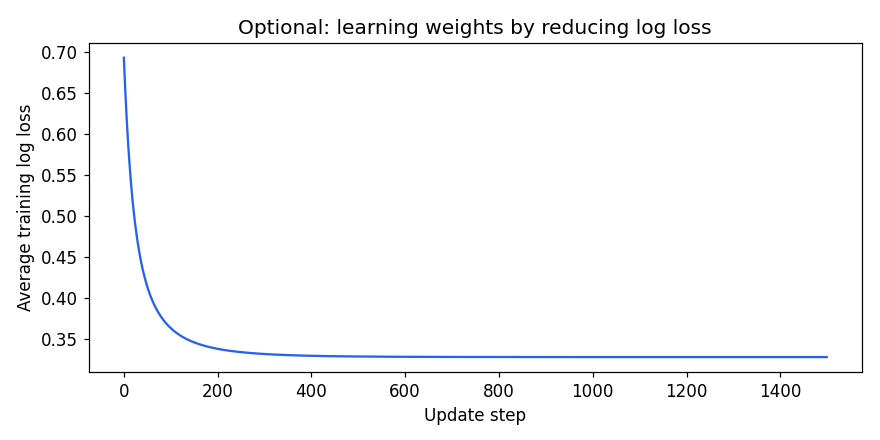

Initial loss: 0.693; final recorded loss: 0.328
Learned standardized-input weight: 2.758; intercept: -0.470


In [12]:
hour_mean = float(X_train['hours_studied'].mean())
hour_std = float(X_train['hours_studied'].std(ddof=0))
x_scaled = (X_train['hours_studied'].to_numpy() - hour_mean) / hour_std
y_array = y_train.to_numpy()
gd_w, gd_b = 0.0, 0.0
learning_rate = 0.1
loss_history = []
for step in range(1500):
    p = sigmoid(gd_b + gd_w * x_scaled)
    safe_p = np.clip(p, 1e-12, 1 - 1e-12)
    loss_history.append(-np.mean(y_array * np.log(safe_p) + (1-y_array) * np.log(1-safe_p)))
    error = p - y_array
    grad_w = np.mean(error * x_scaled)
    grad_b = np.mean(error)
    gd_w -= learning_rate * grad_w
    gd_b -= learning_rate * grad_b

plt.plot(loss_history, color='#2563eb')
plt.xlabel('Update step')
plt.ylabel('Average training log loss')
plt.title('Optional: learning weights by reducing log loss')
plt.tight_layout()
plt.show()
print(f'Initial loss: {loss_history[0]:.3f}; final recorded loss: {loss_history[-1]:.3f}')
print(f'Learned standardized-input weight: {gd_w:.3f}; intercept: {gd_b:.3f}')


## Later topics
Multiple features; categorical encoding; preprocessing pipelines; maximum likelihood; regularization; validation and cross-validation; precision/recall/F1; class imbalance; ROC/PR curves; calibration; multiclass softmax; nonlinear features; coefficient uncertainty; fairness and deployment monitoring.

## Software references
- [Scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html): fitting, probability outputs, and default regularization.
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html): notebook format and runtime information.

Exact fitted coefficients may vary slightly across library versions.
